# Gợi ý sản phẩm kế tiếp bằng RNN

Notebook này đọc trực tiếp log `data/2019-Oct.csv` và `data/2019-Nov.csv`, học chuỗi sản phẩm theo `user_session`, so sánh RNN với baseline phổ biến, vẽ biểu đồ và lưu mô hình để web app sử dụng. Để chạy nhanh trên máy cá nhân, dữ liệu được đọc theo khối; có thể tăng `MAX_ROWS` sau khi kiểm thử.

## 1. Thiết lập

Các hạt giống ngẫu nhiên được cố định để kết quả có thể lặp lại. Thư mục `models/` là đầu ra duy nhất mà ứng dụng web cần.

In [1]:
from pathlib import Path
import json, pickle, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
ROOT = Path.cwd()
if not (ROOT / 'data').exists(): ROOT = ROOT / 'RNN_GoiYSanPham'
DATA_DIR, MODEL_DIR = ROOT / 'data', ROOT / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
CSV_FILES = [DATA_DIR / '2019-Oct.csv', DATA_DIR / '2019-Nov.csv']
assert all(p.exists() for p in CSV_FILES), 'Không tìm thấy hai file CSV trong data/'
print('Project:', ROOT.resolve())
print('TensorFlow:', tf.__version__)

Project: D:\N4_K1\HTTM\Code\TieuLuan\RNN_GoiYSanPham
TensorFlow: 2.22.0-rc0


## 2. Đọc và làm sạch dữ liệu theo từng khối

Hàm `load_events` chỉ lấy các cột cần thiết, loại bỏ dòng thiếu dữ liệu và ghép hai tháng. `MAX_ROWS` là **tổng số dòng tối đa mỗi file**; đặt `None` để đọc toàn bộ khi có đủ RAM/thời gian.

In [2]:
MAX_ROWS = 300_000       # tăng lên 1_000_000+ để có mô hình tốt hơn
CHUNK_SIZE = 100_000
USE_COLUMNS = ['event_time', 'event_type', 'product_id', 'category_code', 'brand', 'price', 'user_session']

def load_events(files, max_rows=MAX_ROWS, chunk_size=CHUNK_SIZE):
    """Đọc có giới hạn từng CSV, trả về event hợp lệ theo thời gian."""
    parts = []
    for path in files:
        taken = 0
        for chunk in pd.read_csv(path, usecols=USE_COLUMNS, chunksize=chunk_size):
            chunk = chunk.dropna(subset=['product_id', 'user_session'])
            chunk = chunk[chunk.event_type.isin(['view', 'cart', 'purchase'])]
            chunk['event_time'] = pd.to_datetime(chunk['event_time'], utc=True)
            parts.append(chunk)
            taken += len(chunk)
            if max_rows is not None and taken >= max_rows:
                break
    events = pd.concat(parts, ignore_index=True)
    return events.sort_values(['user_session', 'event_time']).reset_index(drop=True)

events = load_events(CSV_FILES)
print(f'{len(events):,} events | {events.user_session.nunique():,} sessions')
events.head()

600,000 events | 144,212 sessions


,event_time,event_type,product_id,category_code,brand,price,user_session
0,2019-11-01 06:04:45+00:00,view,4400189,appliances.kitchen.coffee_machine,maxwell,15.42,0001dfff-0bb9-45cc-9753-bc69bb5d166f
1,2019-11-01 03:40:33+00:00,view,1801712,electronics.video.tv,lg,382.25,000201a5-a363-4fd2-9228-ab8148c528c1
2,2019-11-01 03:51:34+00:00,view,1005115,electronics.smartphone,apple,949.47,00020305-cbad-48d4-8ead-d9bd2fae9678
3,2019-11-01 03:52:00+00:00,view,1005129,electronics.smartphone,apple,1337.23,00020305-cbad-48d4-8ead-d9bd2fae9678
4,2019-11-01 04:10:16+00:00,view,50600004,auto.accessories.compressor,NaN,379.91,0002503e-1e78-401f-9da2-1ea2896f09dc


## 3. Khám phá nhanh

Hai biểu đồ cho thấy phân bố loại hành vi và các sản phẩm xuất hiện nhiều nhất. Các sản phẩm phổ biến sẽ được giữ lại trong từ điển để giảm không gian phân lớp.

,count,mean,std,min,25%,50%,75%,max
price,600000.0,288.206946,353.939534,0.0,64.33,160.96,360.08,2574.07


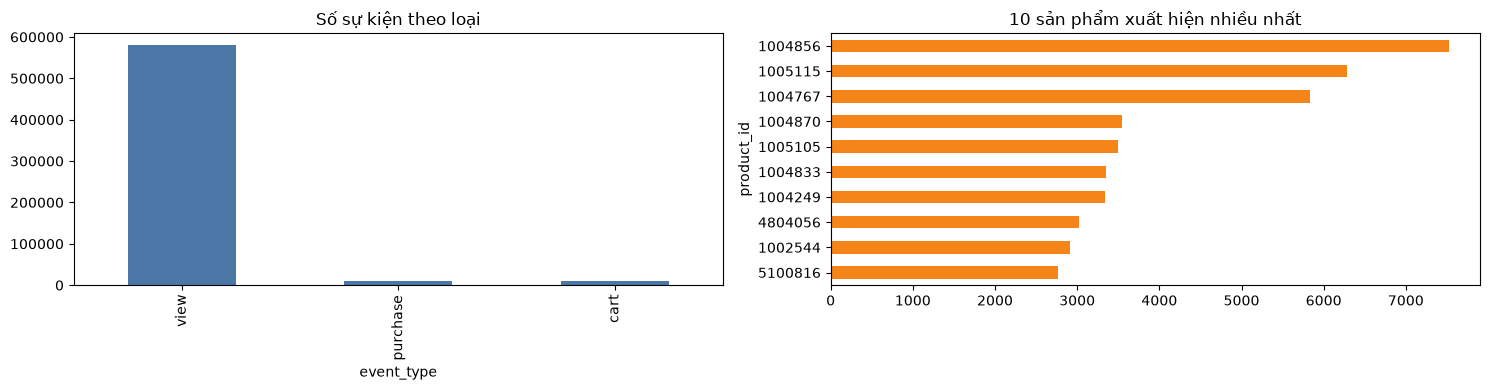

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
events.event_type.value_counts().plot(kind='bar', ax=axes[0], color='#4C78A8', title='Số sự kiện theo loại')
top_raw = events.product_id.value_counts().head(10)
top_raw.sort_values().plot(kind='barh', ax=axes[1], color='#F58518', title='10 sản phẩm xuất hiện nhiều nhất')
plt.tight_layout()
display(events[['price']].describe().T)

## 4. Tạo bài toán học chuỗi

`make_examples` biến mỗi phiên thành nhiều cặp **4 sản phẩm gần nhất → sản phẩm tiếp theo**. `build_catalog` lập từ điển token và lưu thông tin sản phẩm để hiển thị trong web app. Token 0 là padding; sản phẩm ngoài top `VOCAB_SIZE` bị loại để mô hình học ổn định.

In [4]:
SEQ_LEN, VOCAB_SIZE, MAX_EXAMPLES = 4, 800, 80_000

def build_catalog(frame, vocab_size=VOCAB_SIZE):
    """Chọn top sản phẩm và trả về ánh xạ ID thật ↔ token cùng catalog."""
    popular = frame.product_id.value_counts().head(vocab_size).index.astype(str).tolist()
    product_to_token = {product_id: i + 1 for i, product_id in enumerate(popular)}
    token_to_product = {i: product_id for product_id, i in product_to_token.items()}
    catalog = (frame.assign(product_id=frame.product_id.astype(str))
               .query('product_id in @popular')
               .sort_values('event_time').groupby('product_id', as_index=False)
               .agg(brand=('brand', 'last'), category_code=('category_code', 'last'),
                    price=('price', 'median'), popularity=('product_id', 'size')))
    catalog['brand'] = catalog.brand.fillna('Không rõ')
    catalog['category_code'] = catalog.category_code.fillna('Khác')
    return product_to_token, token_to_product, catalog

def make_examples(frame, product_to_token, seq_len=SEQ_LEN, limit=MAX_EXAMPLES):
    """Tạo X dạng (n, seq_len) và nhãn y từ các session có ít nhất seq_len+1 sản phẩm."""
    mapped = frame.assign(token=frame.product_id.astype(str).map(product_to_token)).dropna(subset=['token'])
    X, y = [], []
    for _, group in mapped.groupby('user_session', sort=False):
        tokens = group.token.astype('int32').tolist()
        for end in range(seq_len, len(tokens)):
            X.append(tokens[end-seq_len:end]); y.append(tokens[end])
            if len(y) >= limit:
                return np.asarray(X, dtype='int32'), np.asarray(y, dtype='int32')
    return np.asarray(X, dtype='int32'), np.asarray(y, dtype='int32')

product_to_token, token_to_product, catalog = build_catalog(events)
X, y = make_examples(events, product_to_token)
assert len(X) > 100, 'Hãy tăng MAX_ROWS hoặc giảm VOCAB_SIZE'
print('X:', X.shape, '| y:', y.shape, '| vocabulary:', len(product_to_token) + 1)
catalog.sort_values('popularity', ascending=False).head()

X: (63376, 4) | y: (63376,) | vocabulary: 801


,product_id,brand,category_code,price,popularity
155,1004856,samsung,electronics.smartphone,130.70,7526
226,1005115,apple,electronics.smartphone,975.56,6278
126,1004767,samsung,electronics.smartphone,242.63,5835
160,1004870,samsung,electronics.smartphone,286.86,3549
220,1005105,apple,electronics.smartphone,1348.61,3502


## 5. Tách train/validation/test

Dữ liệu được chia 70% / 15% / 15% với phân tầng theo sản phẩm đích nếu khả thi. Không dùng tập test trong lúc cập nhật trọng số.

In [5]:
try:
    X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=.30, random_state=SEED, stratify=y)
    X_val, X_test, y_val, y_test = train_test_split(X_hold, y_hold, test_size=.50, random_state=SEED, stratify=y_hold)
except ValueError:  # Một số lớp quá hiếm khi mẫu nhỏ
    X_train, X_hold, y_train, y_hold = train_test_split(X, y, test_size=.30, random_state=SEED)
    X_val, X_test, y_val, y_test = train_test_split(X_hold, y_hold, test_size=.50, random_state=SEED)
print('train/val/test:', len(y_train), len(y_val), len(y_test))

train/val/test: 44363 9506 9507


## 6. Mô hình RNN hơn 5 tầng

Kiến trúc có **11 tầng học**: Embedding → SpatialDropout1D → Bidirectional(SimpleRNN) → BatchNormalization → Dropout → GRU → BatchNormalization → Dropout → Dense → Dropout → Dense. SimpleRNN đọc quan hệ gần; GRU giữ ngữ cảnh qua các bước và các tầng dropout/batch normalization giúp tổng quát hóa.

In [6]:
def build_rnn(vocab_size, seq_len=SEQ_LEN):
    """Khởi tạo mạng RNN nhiều tầng để phân loại sản phẩm tiếp theo."""
    model = keras.Sequential([
        keras.layers.Input(shape=(seq_len,), name='history_tokens'),
        keras.layers.Embedding(vocab_size, 96, mask_zero=True, name='embedding'),
        keras.layers.SpatialDropout1D(.15, name='embedding_dropout'),
        keras.layers.Bidirectional(keras.layers.SimpleRNN(80, return_sequences=True), name='bidirectional_rnn'),
        keras.layers.BatchNormalization(name='bn_rnn'),
        keras.layers.Dropout(.20, name='dropout_rnn'),
        keras.layers.GRU(96, name='gru_context'),
        keras.layers.BatchNormalization(name='bn_gru'),
        keras.layers.Dropout(.25, name='dropout_gru'),
        keras.layers.Dense(128, activation='relu', name='dense_features'),
        keras.layers.Dropout(.20, name='dropout_dense'),
        keras.layers.Dense(vocab_size, activation='softmax', name='next_product')
    ], name='ProductNextRNN')
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy',
                  metrics=['sparse_categorical_accuracy', keras.metrics.SparseTopKCategoricalAccuracy(k=5, name='top5_accuracy')])
    return model

model = build_rnn(len(product_to_token) + 1)
model.summary()

Model: "ProductNextRNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 4, 96)          │        76,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_dropout               │ (None, 4, 96)          │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_rnn               │ (None, 4, 160)         │        28,320 │
│ (Bidirectional)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_rnn (BatchNormalization)     │ (None, 4, 160)         │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_rnn (Dropout)           │ (None, 4, 160)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_context (GRU)               │ (None, 96)             │        74,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn_gru (BatchNormalization)     │ (None, 96)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_gru (Dropout)           │ (None, 96)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_features (Dense)          │ (None, 128)            │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_dense (Dropout)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ next_product (Dense)            │ (None, 801)            │       103,329 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 296,289 (1.13 MB)

 Trainable params: 295,777 (1.13 MB)

 Non-trainable params: 512 (2.00 KB)

## 7. Giải thích bằng hợp các hàm

Với lịch sử token $x=(p_{t-4},...,p_{t-1})$, dự đoán là hợp hàm:

$$\hat{p}_t = (f_{softmax} \circ f_{drop} \circ f_{dense} \circ f_{GRU} \circ f_{drop} \circ f_{BN} \circ f_{BiRNN} \circ f_{drop} \circ f_{embed})(x).$$

Trong đó: `f_embed` tra vector sản phẩm; `f_drop` ngẫu nhiên che đặc trưng khi train; `f_BiRNN` quét chuỗi hai chiều; `f_BN` chuẩn hóa kích hoạt; `f_GRU` chọn lọc ký ức bằng các cổng update/reset; `f_dense` kết hợp đặc trưng phi tuyến ReLU; `f_softmax` biến điểm thành xác suất trên mọi sản phẩm. Hàm mất mát là $L=-\log(\hat p_t[y_t])$; Adam tối thiểu hóa trung bình $L$ trên tập train.

## 8. Huấn luyện và lưu checkpoint tốt nhất

Early stopping dừng khi validation loss không cải thiện; checkpoint giữ đúng phiên bản tốt nhất. Cell này vừa train, vừa sinh file `.keras` dùng cho ứng dụng.

In [7]:
model_path = MODEL_DIR / 'rnn_product_recommender.keras'
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(model_path, monitor='val_loss', save_best_only=True)
]
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=15, batch_size=256, callbacks=callbacks, verbose=1)
model.save(model_path)
print('Đã lưu:', model_path)

Epoch 1/15


  1/174 ━━━━━━━━━━━━━━━━━━━━ 13:30 5s/step - loss: 6.8013 - sparse_categorical_accuracy: 0.0000e+00 - top5_accuracy: 0.0039

  4/174 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 6.7199 - sparse_categorical_accuracy: 0.0039 - top5_accuracy: 0.0137     

  7/174 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 6.6700 - sparse_categorical_accuracy: 0.0073 - top5_accuracy: 0.0251

 10/174 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 6.6301 - sparse_categorical_accuracy: 0.0148 - top5_accuracy: 0.0332

...

169/174 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 2.7055 - sparse_categorical_accuracy: 0.4499 - top5_accuracy: 0.6668

171/174 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 2.7052 - sparse_categorical_accuracy: 0.4499 - top5_accuracy: 0.6671

173/174 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - loss: 2.7053 - sparse_categorical_accuracy: 0.4501 - top5_accuracy: 0.6672

174/174 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - loss: 2.7042 - sparse_categorical_accuracy: 0.4503 - top5_accuracy: 0.6673 - val_loss: 2.9720 - val_sparse_categorical_accuracy: 0.4678 - val_top5_accuracy: 0.6456


Đã lưu: D:\N4_K1\HTTM\Code\TieuLuan\RNN_GoiYSanPham\models\rnn_product_recommender.keras


## 9. Đánh giá và so sánh

`Popularity baseline` luôn gợi ý 5 sản phẩm phổ biến nhất ở train. Ta dùng Hit@5 (nhãn đúng xuất hiện trong 5 gợi ý) và MRR@5 (đánh giá vị trí của nhãn đúng); RNN tốt hơn khi hiểu thứ tự hành vi trong phiên.

,Mô hình,Hit@5,MRR@5
0,Popularity baseline,0.074,0.038
1,RNN nhiều tầng,0.649,0.530


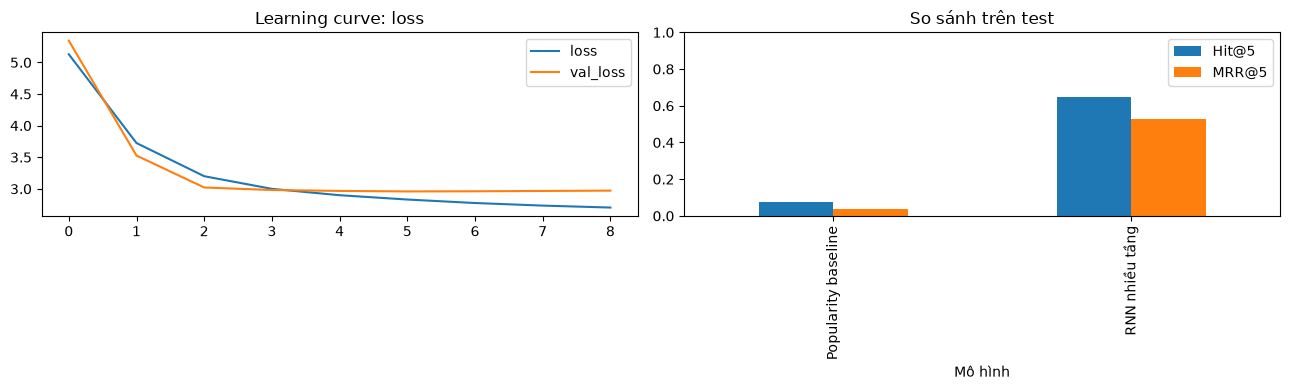

In [8]:
def ranking_scores(probabilities, targets, k=5):
    """Tính Hit@k và MRR@k từ ma trận xác suất và nhãn đúng."""
    top_k = np.argpartition(probabilities, -k, axis=1)[:, -k:]
    hits, reciprocal_ranks = [], []
    for row, target in zip(top_k, targets):
        ranked = row[np.argsort(probabilities[len(hits), row])[::-1]]
        where = np.where(ranked == target)[0]
        hits.append(len(where) > 0)
        reciprocal_ranks.append(1 / (where[0] + 1) if len(where) else 0)
    return float(np.mean(hits)), float(np.mean(reciprocal_ranks))

prob = model.predict(X_test, batch_size=512, verbose=0)
rnn_hit, rnn_mrr = ranking_scores(prob, y_test)
popular_tokens = pd.Series(y_train).value_counts().index[:5].to_numpy()
baseline_prob = np.zeros_like(prob); baseline_prob[:, popular_tokens] = np.arange(5, 0, -1)
base_hit, base_mrr = ranking_scores(baseline_prob, y_test)
comparison = pd.DataFrame({'Mô hình': ['Popularity baseline', 'RNN nhiều tầng'], 'Hit@5': [base_hit, rnn_hit], 'MRR@5': [base_mrr, rnn_mrr]})
display(comparison.style.format({'Hit@5': '{:.3f}', 'MRR@5': '{:.3f}'}))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pd.DataFrame(history.history)[['loss', 'val_loss']].plot(ax=axes[0], title='Learning curve: loss')
comparison.set_index('Mô hình')[['Hit@5', 'MRR@5']].plot(kind='bar', ylim=(0, 1), ax=axes[1], title='So sánh trên test')
plt.tight_layout()

## 10. Xuất artefact cho web app

Hàm này lưu từ điển token, catalog và các tham số tiền xử lý cùng mô hình. Web app dùng chúng để chuyển 4 product ID người dùng nhập thành token và hiển thị sản phẩm gợi ý có thương hiệu, danh mục, giá.

In [9]:
def save_artifacts(destination, product_to_token, token_to_product, catalog, popular_tokens):
    """Lưu tất cả metadata cần thiết cho suy luận ngoài notebook."""
    payload = {'product_to_token': product_to_token, 'token_to_product': token_to_product,
               'sequence_length': SEQ_LEN, 'popular_tokens': popular_tokens.tolist()}
    with open(destination / 'artifacts.pkl', 'wb') as file:
        pickle.dump(payload, file)
    catalog.to_json(destination / 'catalog.json', orient='records', force_ascii=False)

save_artifacts(MODEL_DIR, product_to_token, token_to_product, catalog, popular_tokens)
with open(MODEL_DIR / 'metrics.json', 'w', encoding='utf-8') as file:
    json.dump({'rnn_hit_at_5': rnn_hit, 'rnn_mrr_at_5': rnn_mrr, 'baseline_hit_at_5': base_hit, 'baseline_mrr_at_5': base_mrr}, file, indent=2)
print('Đã xuất model, artifacts.pkl, catalog.json, metrics.json vào', MODEL_DIR)

Đã xuất model, artifacts.pkl, catalog.json, metrics.json vào D:\N4_K1\HTTM\Code\TieuLuan\RNN_GoiYSanPham\models


## 11. Kiểm thử một gợi ý

`recommend` là phiên bản tối giản của luồng suy luận trong Flask: token hóa lịch sử, softmax, lấy top-k và ghép thông tin catalog.

In [10]:
def recommend(history_product_ids, k=5):
    """Trả về k sản phẩm có xác suất cao từ tối đa SEQ_LEN ID gần nhất."""
    tokens = [product_to_token.get(str(p), 0) for p in history_product_ids][-SEQ_LEN:]
    tokens = [0] * (SEQ_LEN - len(tokens)) + tokens
    scores = model.predict(np.asarray([tokens]), verbose=0)[0]
    top = scores.argsort()[-k:][::-1]
    result = catalog.set_index('product_id').reindex([token_to_product[int(t)] for t in top if int(t) in token_to_product]).reset_index()
    result['confidence'] = [float(scores[t]) for t in top if int(t) in token_to_product]
    return result

demo_history = events.product_id.astype(str).head(SEQ_LEN).tolist()
recommend(demo_history)

,product_id,brand,category_code,price,popularity,confidence
0,1005129,apple,electronics.smartphone,1337.23,538,0.387205
1,1005115,apple,electronics.smartphone,975.56,6278,0.057466
2,1005105,apple,electronics.smartphone,1348.61,3502,0.032659
3,1005124,apple,electronics.smartphone,1634.51,475,0.025537
4,1004240,apple,electronics.smartphone,1067.92,130,0.017867
